# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
# using Turing
# using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

# using CairoMakie
# using PairPlots
# using DataFrames

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [2]:
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\FunctionsInferenceScallable.jl")

CompRepUtil_Entro_OEDmc2 (generic function with 1 method)

# Define Priors

In [3]:
priorTheta, priotY0, sampsTh, sampsY0 = genPriorSamps(8000);
bounds, boundY0 = genThetaBounds();


In [4]:
priorInfer =  Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter2_Try1.csv", DataFrame))

8000×17 Matrix{Float64}:
 51.0842  51.23  3.6882e-5    0.0127673  …  347.228   3412.95   0.848161
 59.3126  51.23  7.08156e-5   0.0160709     585.944   2512.62   0.723606
 50.4575  51.23  8.57547e-5   0.013771      155.54    1238.44   1.05155
 59.4274  51.23  9.2772e-5    0.0162965     208.202   1040.38   0.955434
 52.8556  51.23  8.38459e-5   0.0129141     176.512   1365.46   0.932322
 57.8571  51.23  7.22149e-5   0.014015   …  137.962    702.931  0.724618
 59.3414  51.23  6.60347e-5   0.0184151      72.698    700.161  0.911757
 53.5074  51.23  7.84641e-5   0.0142629     831.498    722.756  0.946282
 56.8377  51.23  0.0001183    0.0137294     362.719   1001.77   1.09514
 57.8405  51.23  7.58862e-5   0.0154922     785.659   1670.32   0.991109
  ⋮                                      ⋱               ⋮      
 57.9547  51.23  9.41353e-5   0.0160193     273.485   4821.19   0.958243
 55.2586  51.23  7.57706e-5   0.0149029     169.592   3209.44   1.01351
 52.6042  51.23  0.000101265  0.01242

# Compute Objective Function for All Available Experiments

In [5]:
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:14];
global sampsY0 = priorInfer[:,15:end];

pyrs = [0.6, 0.8, 1.6, 3.2, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29, 40]
# pyrs = [0.6, 0.8, 1.6, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29, 40] # At each iteration we remove past experiments

objs = zeros(length(pyrs))

for i in 1:length(pyrs)
    objs[i] = CompRepUtil_Entro_OEDmc2([pyrs[i]])
end

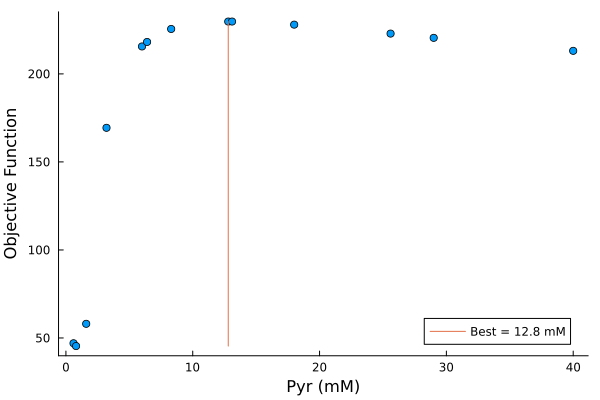

In [35]:
bstIn = findfirst(round.(objs, digits =2) .== maximum(round.(objs, digits = 2)))

scatter(pyrs, objs, label = "", grid = false, ylabel = "Objective Function", xlabel = "Pyr (mM)")
plot!([pyrs[bstIn], pyrs[bstIn]], [minimum(objs), objs[bstIn]], label = "Best = "*string(pyrs[bstIn])*" mM")

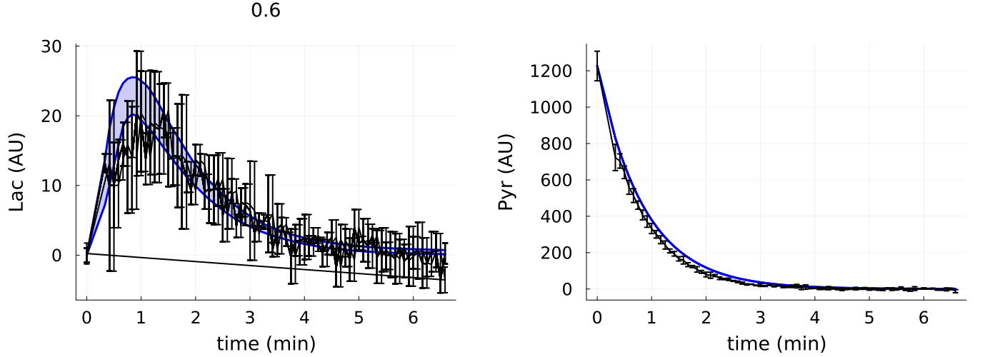

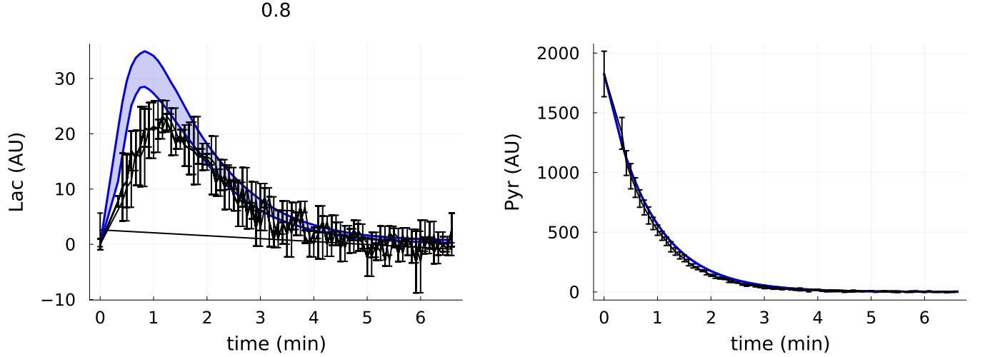

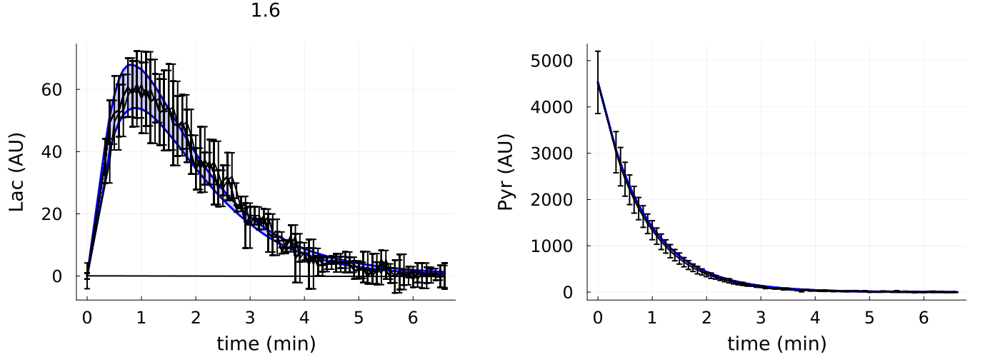

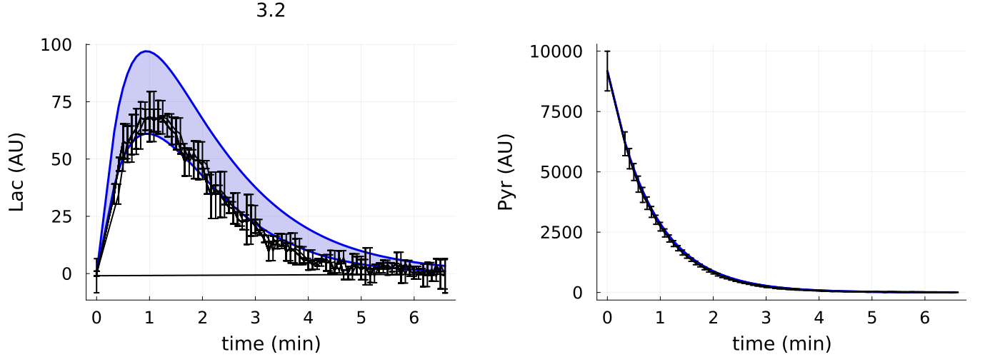

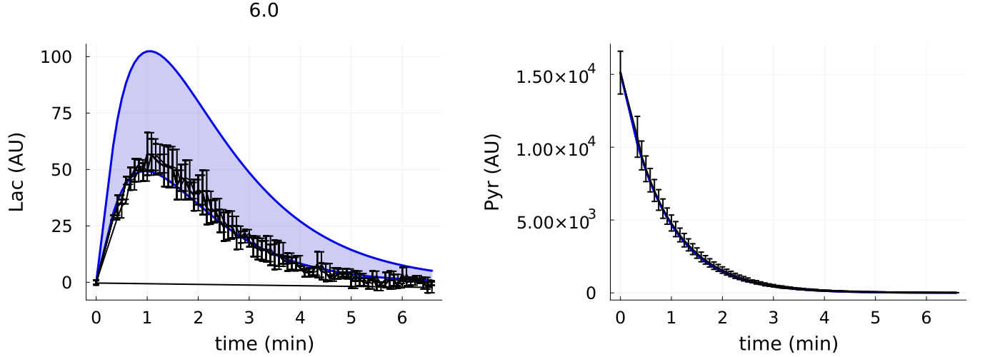

...

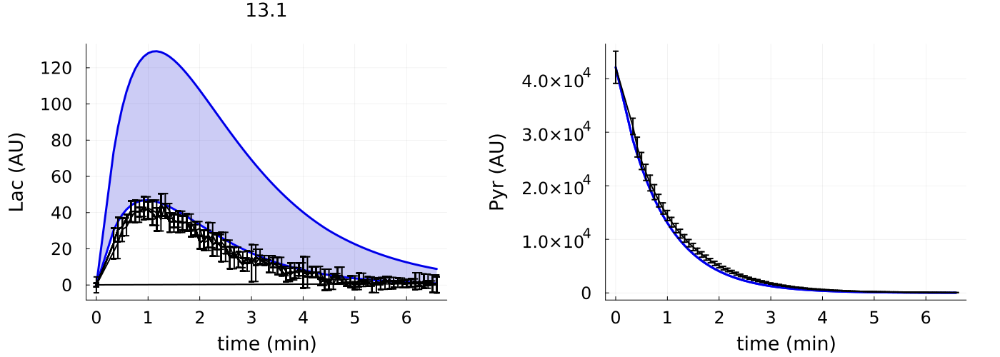

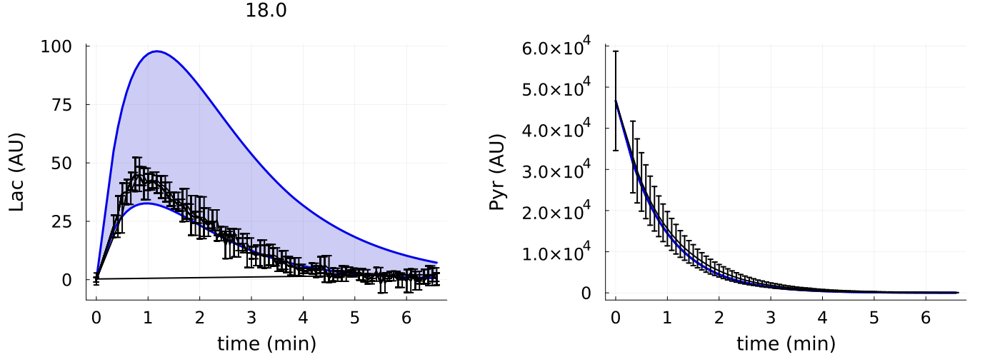

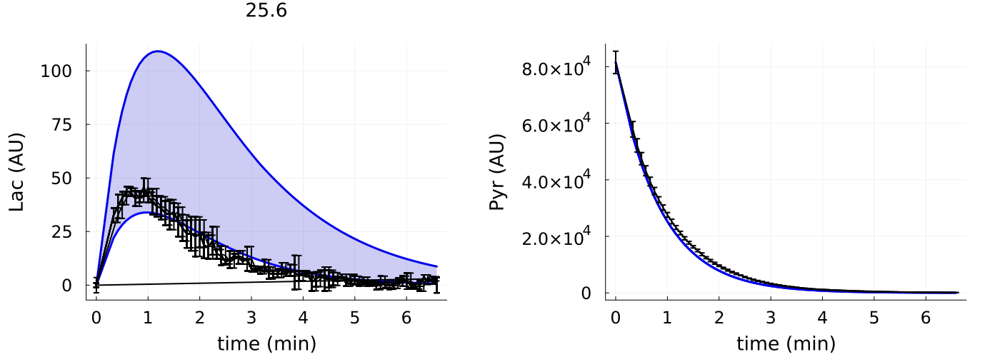

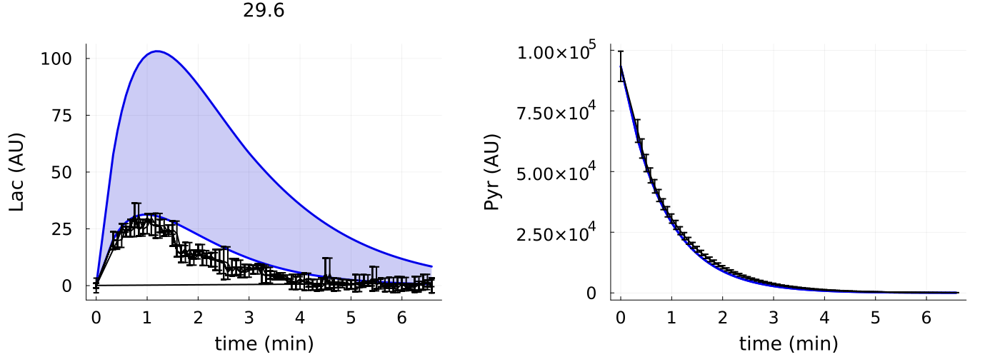

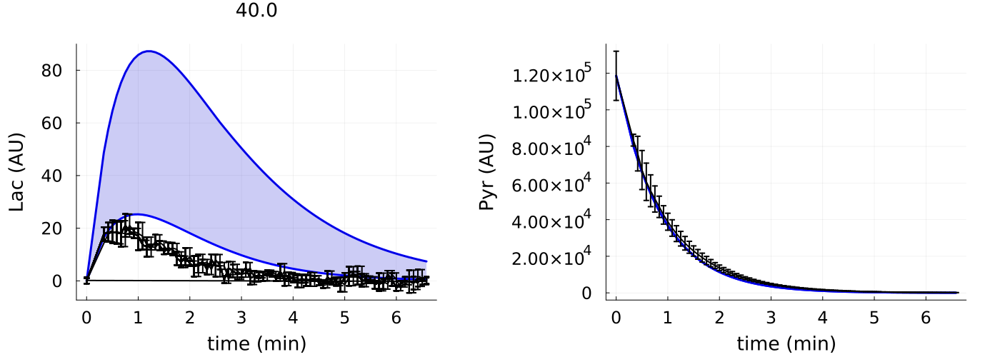

In [7]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths2 = [mainpath*"3Mil_0-6mMPyr_Dat.csv", mainpath*"3Mil_0-8mMPyr_Dat.csv", mainpath*"3Mil_1-6mMPyr_Dat.csv", mainpath*"3Mil_3-2mMPyr_Dat.csv", mainpath*"3Mil_6-0mMPyr_Dat.csv", 
          mainpath*"3Mil_6-4mMPyr_Dat.csv", mainpath*"3Mil_8-3mMPyr_Dat.csv", mainpath*"3Mil_12-8mMPyr_Dat.csv", mainpath*"3Mil_13-1mMPyr_Dat.csv", mainpath*"3Mil_18-0mMPyr_Dat.csv", 
          mainpath*"3Mil_25-6mMPyr_Dat.csv", mainpath*"3Mil_29-6mMPyr_Dat.csv", mainpath*"3Mil_40-0mMPyr_Dat.csv", ];
conce2 = [0.6, 0.8, 1.6, 3.2, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29.6, 40];


Random.seed!(8987654);
global datAll = restructDatInfCompRep_RealExpDat_Scal(paths2, conce2, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], [3e6])




simPriorPredictAll(200, datAll, priorInfer[:,1:14], priorInfer[:,15:end], conce2)

# Extract Experimental Data

In [33]:
pyrs[bstIn]

12.8

In [9]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_0-6mMPyr_Dat.csv", mainpath*"3Mil_1-6mMPyr_Dat.csv", 
         mainpath*"3Mil_"*replace(string(pyrs[bstIn]), "." => "-", count = 1)*"mMPyr_Dat.csv"];
conce = [0.6, 1.6, pyrs[bstIn]];


Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat_Scal(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], [3e6])

Dict{String, Any} with 16 entries:
  "Means"  => [1226.15 4528.94 42116.7; 723.012 3020.78 31083.7; … ; 0.320623 -…
  "stsl"   => [77 77 77]
  "obSta"  => [1 2]
  "sts"    => [0 0 0; 20 20 20; … ; 390 390 390; 395 395 395]
  "obser"  => 2
  "Y0us"   => [600.0 1600.0 13100.0; 0.0 0.0 0.0; … ; 0.0 0.0 0.0; 1226.15 4528…
  "ts"     => [1.0e-20 1.0e-20 1.0e-20; 1.0 1.0 1.0; … ; 394.0 394.0 394.0; 395…
  "itp"    => [0.0, 0.0, 0.0]
  "ScFms"  => [17.0298 23.5882 26.7918]
  "ncells" => [4 4 4]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [81.2187 672.75 3001.28; 72.3012 445.178 1519.15; … ; 4.42203 5.2…
  "m"      => 3
  "nmCls"  => [3.0e6 3.0e6 3.0e6]
  "nts"    => [395 395 395]

# Simulate Experiment Prior Prediction
CAREFUL!!! Simulations take a minute or more if you take all the samples!

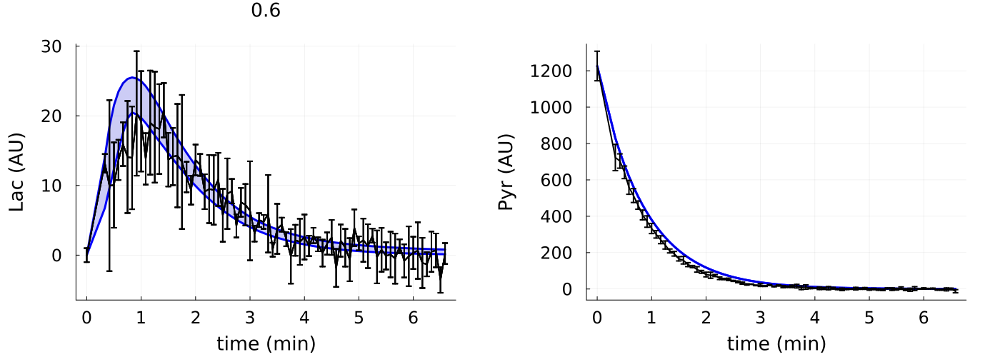

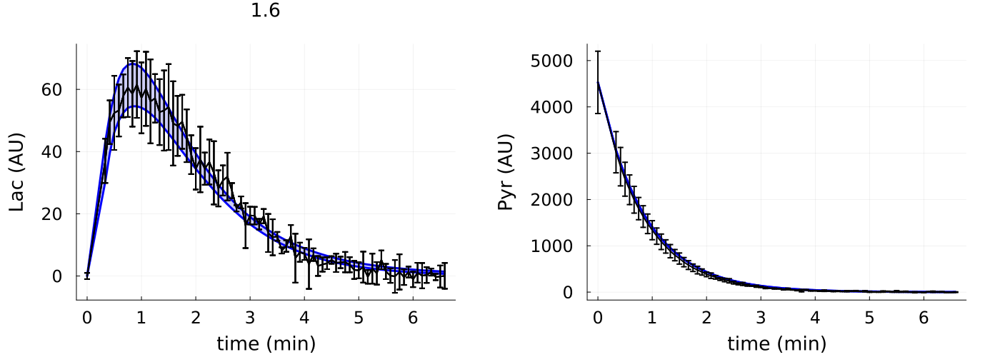

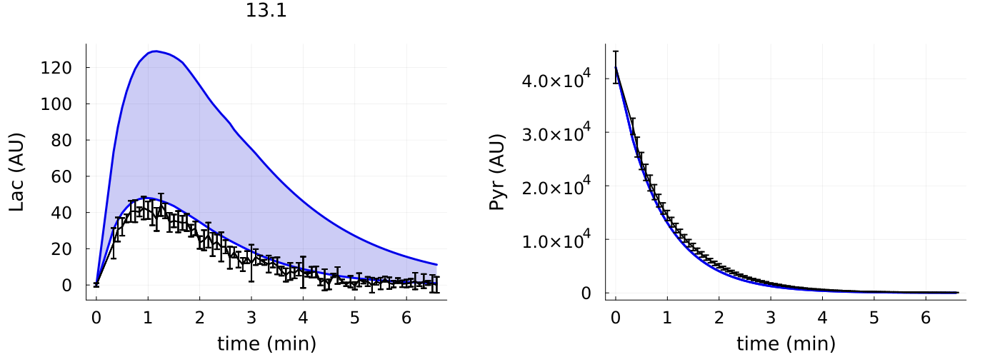

In [10]:
simPriorPredictAll(2000, dat, priorInfer[:,1:14], priorInfer[:,15:end], conce)

# MLE to obtain a good first guess for inference

In [11]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 3e6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE2(p)

8.691838098464708e15

In [12]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE2; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:13], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*15, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.51 secs, 56 evals, 29 steps, improv/step: 0.414 (last = 0.4138), fitness=1782.686749344
1.01 secs, 101 evals, 58 steps, improv/step: 0.448 (last = 0.4828), fitness=1782.686749344
1.51 secs, 166 evals, 105 steps, improv/step: 0.467 (last = 0.4894), fitness=1634.935640533
2.02 secs, 233 evals, 156 steps, improv/step: 0.423 (last = 0.3333), fitness=1599.576192417
2.53 secs, 306 evals, 216 steps, improv/step: 0.421 (last = 0.4167), fitness=1599.576192417
3.03 secs, 374 evals, 274 steps, improv/step: 0.387 (last = 0.2586), fitness=1599.576192417
3.54 secs, 433 evals, 330 steps, improv/step: 0.364 (last = 0.2500), fitness=1421.776925327
4.04 secs, 488 evals, 382 steps, improv/step: 0.374 (last = 0.4423), fitness=1421.776925327
4.63 secs, 558 evals, 449 steps, improv/step: 0.354 (last = 0.2

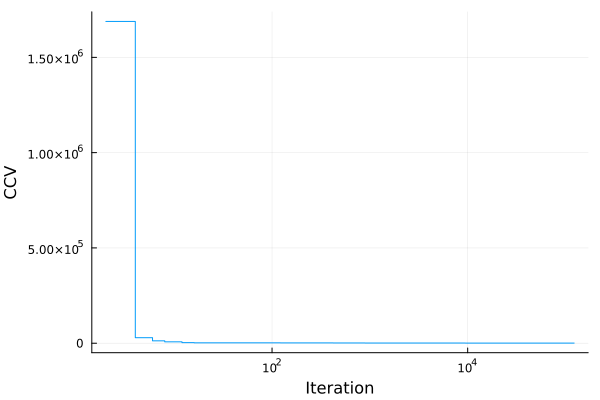

┌ Warning: Attempting to store var"#107#108".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [13]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

# Extract Parameter Vector
parfitT = zeros(16, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind];

# Save Data
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMTRRCmp_Exper_Iter3.jld2", "FitsT",FitsT)
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter3.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

In [14]:
# Load Data
ppT = JLD2.load("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter3.jld2")["resMMat"][:,1]

16-element Vector{Float64}:
  52.439459101275155
  51.23
   8.372641360744225e-5
   0.016379654673091583
   1.6793958150902726e-8
   0.21168276498951205
   1.9999976065513603
   0.3543881477481706
   0.35666065012132037
   2.148284586642797e-9
   1.9999996652039145
   3.1577271832416367e-9
   3.0e6
 742.2963606431206
 112.93775218326809
   1.1679999803098087

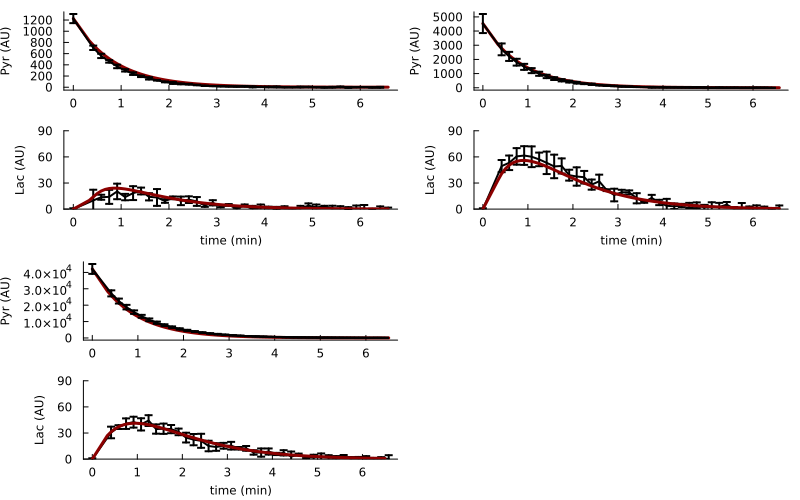

In [15]:
pst = Array{Any}(undef, length(conce))
i = 1
for i in 1:length(conce)
     tsC2 = dat["sts"][:,i];
     if i == 3
          tsC2 = dat["sts"][1:end-1,3];
     end
     ts = 0:tsC2[end];
     ivss = [round(conce[i], digits = 1)*1000, 0, 0, ppT[14], ppT[15], ppT[16], 0, 0, 0, 0, 0, round(conce[i], digits = 1)*1000, 0, round(conce[i], digits = 1)*1000*(dat["ScFms"][i]*0.12)];;
     samps = convert.(Int, tsC2);

     SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp_Scall(ts, vcat(ppT[1:13], dat["ScFms"][i], 0), ivss, samps);

     pps = plot(dat["sts"][1:2:end,i]./60, dat["Means"][1:2:end,i,2], yerror = dat["Erros"][1:2:end,i,2], linewidth = 2, colour = "black", label = "",
               margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18),
               xlabel = "time (min)", ylabel = "Lac (AU)", size = (800,500))

          plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4", label = "", grid = false, ylim=(0,90))


     ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4", label = "", grid = false,
          margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18))
     plot!(dat["sts"][1:2:end-1,i]./60, dat["Means"][1:2:end-1,i,1], yerror = dat["Erros"][1:2:end-1,i,1], linewidth = 2, colour = "black", label = "", ylabel = "Pyr (AU)")

     pst[i] = plot(ps, pps, layout=(2,1))
end

plot(pst...)

## Compute structure for Stan's initial guess

In [16]:
jj = vcat(1, 3:12)

preTrans = zeros(14);

for i in 1:length(jj)
    
    if i == 1
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].μ)/priorTheta[jj[i]].σ;
    else
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].untruncated.μ)/priorTheta[jj[i]].untruncated.σ;
    end
    
end
kk = [14,15,16]
for i in 1:length(priotY0)
    preTrans[i+11] = (ppT[kk[i]]-priotY0[i].untruncated.μ)/priotY0[i].untruncated.σ;
end


samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict2(repeat(preTrans, 1, 10), names)

ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => -0.999284
  "LDH"  => 4.00674
  "kin"  => -0.966509
  "ki"   => 1.10526
  "kunE" => 2.56661
  "kpl"  => -0.404376
  "NADH" => 1.19872
  "kup"  => -0.62696
  "T1_X" => 1.15195
  "kbp"  => 1.10526
  "kr"   => -0.999996
  "NAD"  => -2.38824
  "kun"  => 0.411218
  "kbn"  => -0.966412

# Inference

In [18]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\HP_PyrLac_CmpRepresMo_Scallable2.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_Iter3_Try1", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 200, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.9;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=11;
# StanModel.method.algorithm.stepsize_jitter = 0.5;

# StanModel = Stanmodel(name="PyrCompRepr_Iter2_Try1", model=Model, nchains =10,
#             num_samples  = 800, num_warmup = 400, printsummary=true);
# StanModel.method.save_warmup = true;
# StanModel.method.adapt.delta = 0.90;
# StanModel.method.algorithm.stepsize = 0.1;
# StanModel.method.algorithm.engine.max_depth=10;
# StanModel.method.algorithm.stepsize_jitter = 0.5;

11

In [19]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_Iter3_Try1_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(200,200,200,200,200,200,200,200,200,200); thin=(1,1,1,1,1,1,1,1,1,1); 10000 iterations saved.

Warmup took (22415, 20619, 25110, 18350, 23068, 24947, 19322, 19225, 21100, 18096) seconds, 59 hours total
Sampling took (65630, 84464, 80868, 56177, 65865, 82509, 53487, 93870, 108121, 64240) seconds, 210 hours total

                    Mean     MCSE   StdDev        5%       50%       95%    N_Eff  N_Eff/s    R_hat

lp__            -5.9e+02  6.8e-02  3.1e+00  -6.0e+02  -5.9e+02  -5.9e+02  2.0e+03  2.7e-03  1.0e+00
accept_stat__       0.95  1.1e-02  8.5e-02   7.7e-01      0.98      1.00  6.0e+01  8.0e-05  1.1e+00
stepsize__         0.011  1.3e-03  3.0e-03   6.6e-03     0.011     0.017  5.0e+00  6.6e-06  7.4e+13
treedepth__          8.3  1.6e-01  6.0e-01   7.0e+00       8.0       9.0  1.3e+01  1.8e-05  1.3e+00
n_leapfrog__         424  4.4e+01  1.8e+02   2.6e+02 

(0, [-618.688 0.868337 … 124.466 1.20658; -618.688 0.0 … 124.466 1.20658; … ; -591.751 0.949475 … 3125.04 1.27671; -591.177 0.832693 … 2457.56 1.2368;;; -615.109 0.782657 … 4859.3 1.04963; -615.109 0.0 … 4859.3 1.04963; … ; -592.744 0.883055 … 2789.91 1.06841; -598.738 0.996814 … 4109.08 1.05113;;; -617.137 0.147335 … 82.8246 1.12658; -617.137 0.0 … 82.8246 1.12658; … ; -593.905 0.993031 … 2339.94 0.942198; -592.271 0.93179 … 4420.89 1.11494;;; -614.041 0.908783 … 625.234 0.998633; -614.041 0.0 … 625.234 0.998633; … ; -594.21 0.980852 … 2397.32 1.09733; -594.756 0.963871 … 2406.39 1.12299;;; -615.584 0.456831 … 96.1812 0.981053; -615.584 0.0 … 96.1812 0.981053; … ; -595.507 0.939586 … 1990.61 0.958568; -591.245 0.999376 … 5272.71 1.12358;;; -614.335 0.976787 … 103.362 1.14302; -614.335 0.0 … 103.362 1.14302; … ; -590.819 0.922084 … 3435.31 1.08776; -591.359 0.991376 … 4786.65 1.17433;;; -611.691 0.781277 … 1884.04 0.839302; -611.691 0.0 … 1884.04 0.839302; … ; -589.636 0.986466 … 3637.

In [22]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PyrCompetitiveRepressionInferExpScal_Iter3_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

poster = vcat(chns[201:end, end-16:end, 1], chns[201:end, end-16:end, 2], chns[201:end, end-16:end, 3], chns[201:end, end-16:end, 4], chns[201:end, end-16:end, 5], 
              chns[201:end, end-16:end, 6], chns[201:end, end-16:end, 7], chns[201:end, end-16:end, 8], chns[201:end, end-16:end, 9], chns[201:end, end-16:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter3_Try1.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter3_Try1.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter3_Try1.csv"

In [23]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter3_Try1.csv", DataFrame))

8000×17 Matrix{Float64}:
 52.8891  51.23  8.183e-5     0.0172027  …  150.857   3582.14  1.23228
 50.3012  51.23  9.18842e-5   0.015604      532.806   4245.35  0.949655
 54.2562  51.23  7.69785e-5   0.0174347     373.833   4302.07  1.06196
 53.9775  51.23  7.61161e-5   0.0174482     382.129   4527.82  1.027
 54.6025  51.23  0.000161242  0.0165238     138.572   1959.14  1.40481
 50.1868  51.23  8.8182e-5    0.0163999  …  123.676   4563.16  1.13292
 53.3726  51.23  6.98111e-5   0.0173437     458.008   2123.0   0.900556
 51.4299  51.23  0.000104819  0.0156317     574.051   4852.92  1.12186
 44.5492  51.23  7.46909e-5   0.0148197      63.6578  2103.79  1.08662
 42.971   51.23  7.09315e-5   0.0139074      50.5218  3804.24  1.01128
  ⋮                                      ⋱               ⋮     
 52.1399  51.23  9.09052e-5   0.0161877     435.676    898.75  1.02241
 52.9884  51.23  0.000106096  0.0160923     511.049   6027.31  1.11665
 53.2407  51.23  0.000107196  0.0162658     576.234   4690.

# Plot Posterior VS Prior

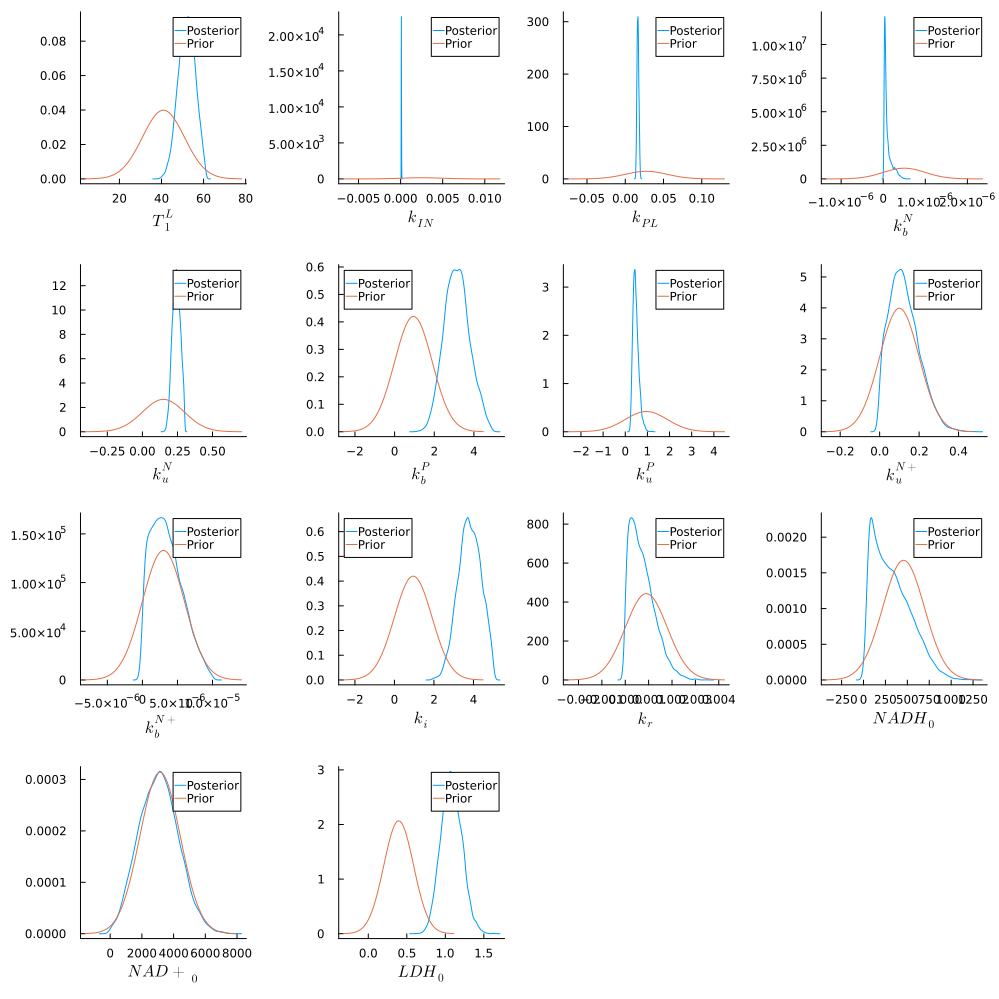

In [24]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"];

indss=vcat(1, 3:12, 15:17)
prisDis = vcat(priorTheta, priotY0)

pltsPost = Array{Any}(undef, length(indss))

for i in 1:length(indss)

    pltsPost[i] = plot(kde(poster[:,indss[i]]), label = "Posterior", xlabel = namess[i])
    try
        plot!(prisDis[indss[i]].untruncated, label = "Prior")
    catch
        plot!(prisDis[indss[i]], label = "Prior")
    end

end

plot(pltsPost..., size=(1000,1000), grid = false)

In [25]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,15:end]))))

110.47878869698651

In [65]:
using CairoMakie
using PairPlots
using DataFrames

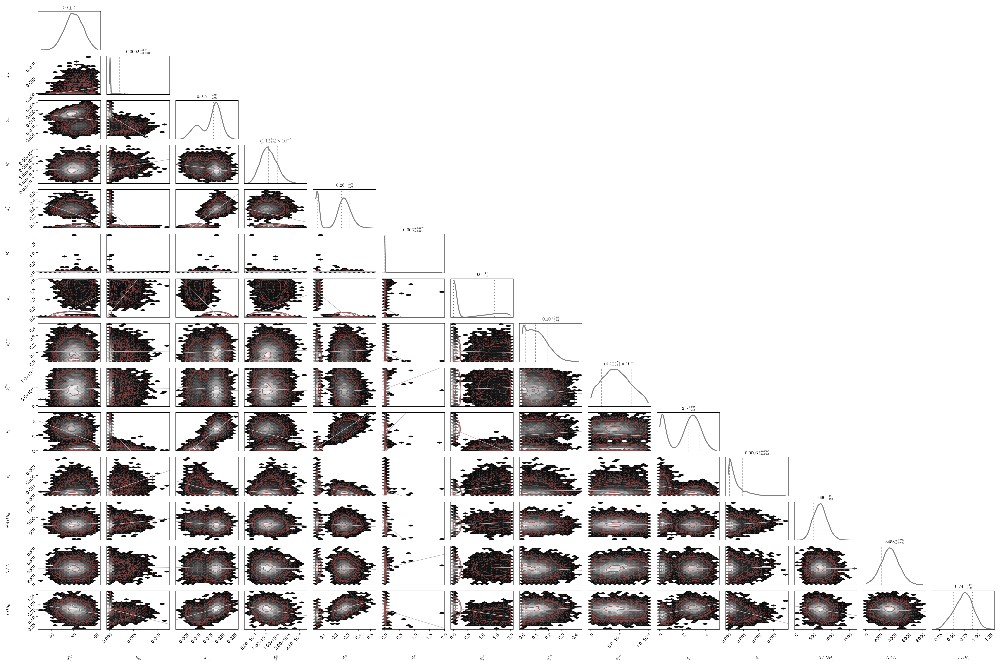

In [66]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,15:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

# save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_InitialExperiment.svg", fig)


fig

# Simulate Experiment Current Posterior

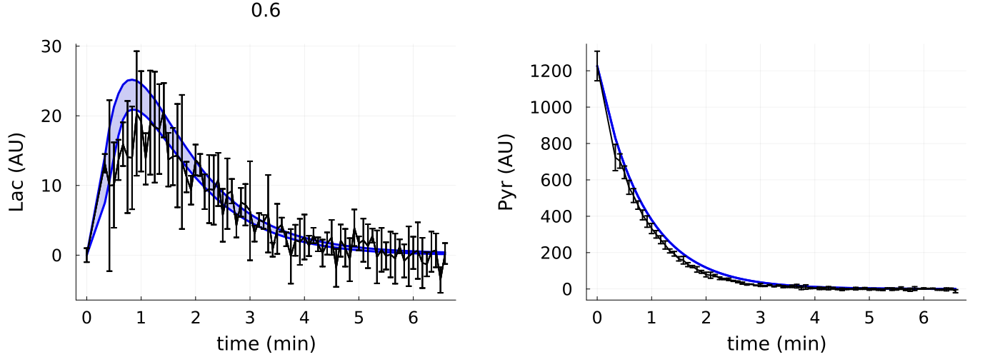

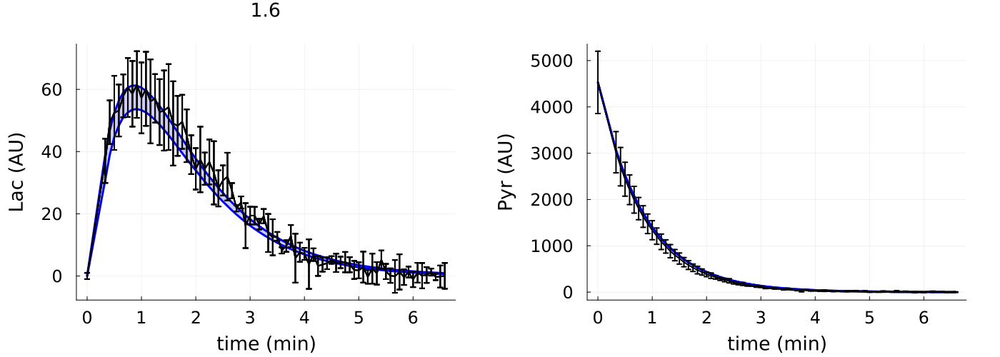

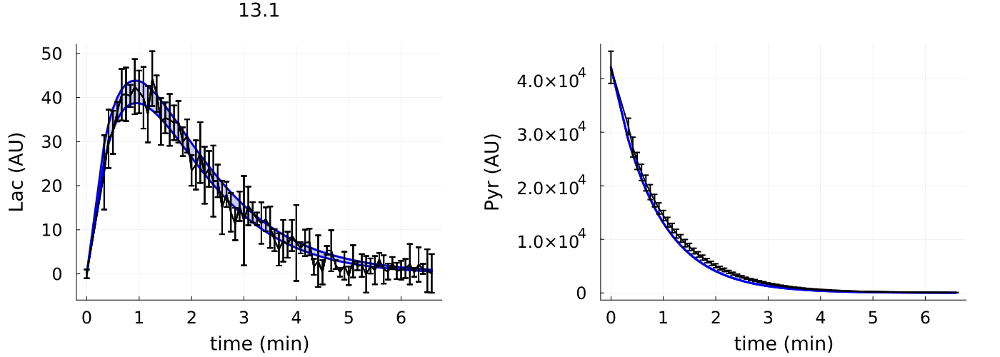

In [28]:
simPriorPredictAll(2000, dat, poster[:,1:14], poster[:,15:end], conce)